In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
np.random.seed(42)

N = 200_000

data = np.random.randint(1, 101, size=N)

print("Number of elements:", len(data))
print("First 10 values:", data[:10])
print("Average:", np.mean(data))
print("Minimum:", np.min(data))
print("Maximum:", np.max(data))

int8_data = data.astype(np.int8)
int32_data = data.astype(np.int32)
float32_data = data.astype(np.float32)
float64_data = data.astype(np.float64)

arrays = {
    "uint8": int8_data,
    "int32": int32_data,
    "float32": float32_data,
    "float64": float64_data
}

print("MEMORY COMPARISON")
print("-" * 40)

for name, arr in arrays.items():
    print(
        f"{name:10} | "
        f"Item size: {arr.itemsize} bytes | "
        f"Total memory: {arr.nbytes / 1024:.2f} KB"
    )
value = 1 / 3

float32_value = np.float32(value)
float64_value = np.float64(value)

print("Original value:", value)
print("Float32 value:", float32_value)
print("Float64 value:", float64_value)

print("\nData types:")
print("Float32:", float32_value.dtype)
print("Float64:", float64_value.dtype)


Number of elements: 200000
First 10 values: [52 93 15 72 61 21 83 87 75 75]
Average: 50.47343
Minimum: 1
Maximum: 100
MEMORY COMPARISON
----------------------------------------
uint8      | Item size: 1 bytes | Total memory: 195.31 KB
int32      | Item size: 4 bytes | Total memory: 781.25 KB
float32    | Item size: 4 bytes | Total memory: 781.25 KB
float64    | Item size: 8 bytes | Total memory: 1562.50 KB
Original value: 0.3333333333333333
Float32 value: 0.33333334
Float64 value: 0.3333333333333333

Data types:
Float32: float32
Float64: float64


In [ ]:
import numpy as np
import time

np.random.seed(42)

N = 200_000
data = np.random.randint(1, 101, size=N)

print("Dataset created:", len(data))
sample = data[:N]

def python_method(arr):
    total = 0

    for value in arr:
        total += int(value) * int(value)

    return total


def numpy_method(arr):
    values = arr.astype(np.int64)
    return np.sum(values * values)


python_result = python_method(sample)
numpy_result = numpy_method(sample)

print("Python result:", python_result)
print("NumPy result:", numpy_result)
print("Results match:", python_result == numpy_result)

def benchmark(function, arr, repeats=5):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        function(arr)
        end = time.perf_counter()

        times.append(end - start)

    return np.median(times)


python_time = benchmark(python_method, sample)
numpy_time = benchmark(numpy_method, sample)

print(f"Python loop time: {python_time:.6f} seconds")
print(f"NumPy time:       {numpy_time:.6f} seconds")

if numpy_time > 0:
    speedup = python_time / numpy_time
    print(f"Speedup: {speedup:.2f}x")

Dataset created: 200000
Python result: 676645304
NumPy result: 676645304
Results match: True
Python loop time: 0.034037 seconds
NumPy time:       0.000553 seconds
Speedup: 61.52x


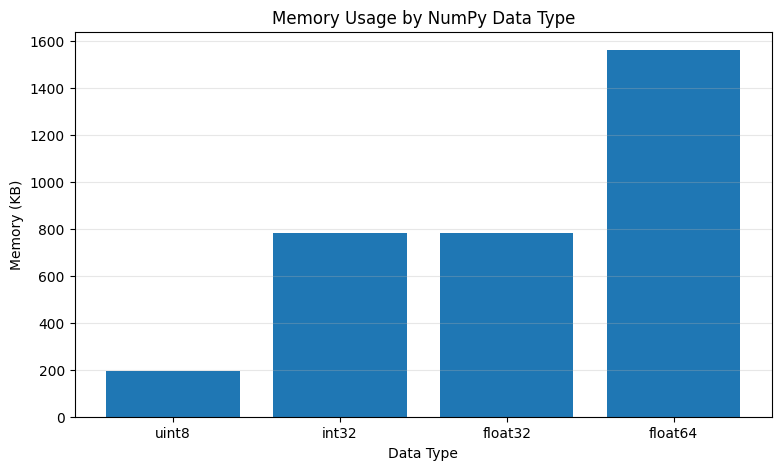

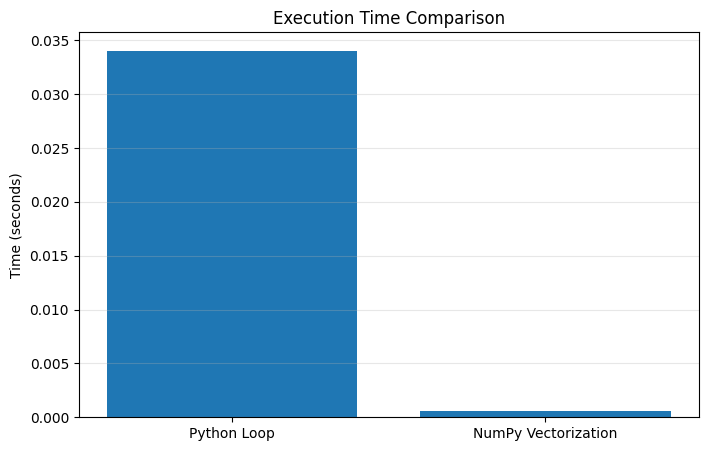

PROJECT OBSERVATIONS
----------------------------------------
Memory-efficient data type: uint8
Python loop took 0.034037 seconds.
NumPy vectorization took 0.000553 seconds.
NumPy was faster in this experiment.

Conclusion:
Data type selection affects memory usage, while vectorized operations can improve numerical performance.


In [ ]:
memory_kb = [
    arr.nbytes / 1024
    for arr in arrays.values()
]

plt.figure(figsize=(9, 5))
plt.bar(arrays.keys(), memory_kb)

plt.title("Memory Usage by NumPy Data Type")
plt.xlabel("Data Type")
plt.ylabel("Memory (KB)")
plt.grid(axis="y", alpha=0.3)

plt.show()
methods = ["Python Loop", "NumPy Vectorization"]
execution_times = [python_time, numpy_time]

plt.figure(figsize=(8, 5))
plt.bar(methods, execution_times)

plt.title("Execution Time Comparison")
plt.ylabel("Time (seconds)")
plt.grid(axis="y", alpha=0.3)

plt.show()
smallest_memory = min(
    arrays,
    key=lambda name: arrays[name].nbytes
)

print("PROJECT OBSERVATIONS")
print("-" * 40)

print("Memory-efficient data type:", smallest_memory)

print(
    f"Python loop took {python_time:.6f} seconds."
)

print(
    f"NumPy vectorization took {numpy_time:.6f} seconds."
)

if numpy_time < python_time:
    print("NumPy was faster in this experiment.")
else:
    print("NumPy was not faster in this particular run.")

print("\nConclusion:")
print(
    "Data type selection affects memory usage, while "
    "vectorized operations can improve numerical performance."
)